# Scaling and metric geometry of feed-forward reconstruction

**What this notebook does.** Notebook 02 scored the *cameras*. This one asks the two questions
a robotics engineer asks next:

1. **How many frames can I feed?** Runtime, peak VRAM and pose accuracy of VGGT-1B and
   Depth Anything 3 (Base, Large-1.1) as the number of input views grows from 2 to 128
   (South Building, frames spread over the whole 128-photo collection), measured on an 8 GB
   laptop GPU by `benchmark.py`.
2. **How good is the dense geometry in metres?** On TUM RGB-D fr1_desk we have Kinect depth
   and motion-capture poses. The Sim(3) alignment of the predicted cameras to the mocap
   trajectory gives each reconstruction a **metric scale**; with it we evaluate the predicted
   depth maps against the Kinect and the fused point cloud against a Kinect + mocap
   reference cloud (accuracy / completeness, in centimetres).

**What you'll learn**
- the token arithmetic behind the cost of all-to-all attention, $\mathcal O\big((N P)^2\big)$
  compute and roughly linear memory with flash attention;
- how to read a runtime / memory scaling curve and find the frame budget of a GPU;
- per-frame median scaling vs. one global scale: what each depth protocol measures;
- how to turn an up-to-scale reconstruction into a metric point cloud with a known trajectory,
  and how to score it with accuracy / completeness (Chamfer) distances.

**Prerequisites:** notebooks 01 and 02 of this project, depth metrics from project 08.
Everything here is loaded from the caches of `benchmark.py` (`runs/10_feedforward_3d/preds/`,
`projects/10_feedforward_3d/results/scaling.csv`); no model runs in this notebook.

## Setup

In [1]:
# --- Setup: imports, device, repository paths, plotting style ---
# The project helpers live in projects/10_feedforward_3d/scripts/ff3d.py (shared with the
# benchmark script and the solutions), so every number below comes from the same code.
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cvlab import viz
from cvlab.device import setup
from cvlab.io import outputs_dir, project_dir

PROJECT = "10_feedforward_3d"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import ff3d  # noqa: E402

device = setup(seed=0)
viz.set_style()
pd.set_option("display.precision", 3)
print("results dir:", ff3d.rel(ff3d.results_path()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)
results dir: projects/10_feedforward_3d/results


## 1. The token budget
VGGT cuts every image into $14\times14$ patches, so a $W\times H$ input gives
$P = \tfrac{W}{14}\cdot\tfrac{H}{14}$ patch tokens plus 5 special tokens per frame. Each of the
24 global-attention layers lets all $T = N(P+5)$ tokens attend to each other:

$$\text{FLOPs per global layer} \approx 4\,T^2 d \quad(\text{QK}^\top\text{ and AV}),\qquad d = 1024 .$$

Flash attention never materialises the $T\times T$ matrix, so **memory** grows linearly with
$N$ (activations and the DPT heads) while **compute** grows quadratically. The frame-wise
layers, the MLPs and the heads are linear in $N$ and dominate for small $N$; the quadratic term
takes over as $N$ grows. DA3 has the same structure (a DINOv2 ViT with cross-view attention).

In [2]:
# --- Tokens and attention cost vs number of frames (South Building, 1024x768 photos) ---
# VGGT 'crop' pre-processing: width 518, height rounded to a multiple of 14 -> 518x392.
# DA3 'upper_bound_resize' at 504: longest side 504 -> 504x378.
rows = []
for n in [2, 8, 24, 64, 128]:
    for model, (w, h), d in [("VGGT-1B", (518, 392), 1024), ("DA3-Base", (504, 378), 768)]:
        P = (w // 14) * (h // 14)  # patch tokens per frame
        T = n * (P + 5)  # tokens seen by one global-attention layer
        rows.append({"frames": n, "model": model, "tokens / frame": P + 5, "total tokens": T,
                     "attention GFLOP / layer": 4 * T**2 * d / 1e9})
tokens = pd.DataFrame(rows).pivot(index="frames", columns="model",
                                  values=["total tokens", "attention GFLOP / layer"])
tokens.round(0)

total tokens           attention GFLOP / layer         
model      DA3-Base   VGGT-1B                DA3-Base  VGGT-1B
frames                                                        
2            1954.0    2082.0                    12.0     18.0
8            7816.0    8328.0                   188.0    284.0
24          23448.0   24984.0                  1689.0   2557.0
64          62528.0   66624.0                 12011.0  18181.0
128        125056.0  133248.0                 48043.0  72725.0

## 2. Measured scaling on the GPU
`benchmark.py` loaded each model once, ran a 2-frame warm-up and then fed
$N \in \{2, 4, 8, 16, 24, 32, 48, 64, 96, 128\}$ South Building photos (evenly spaced over the
128-photo collection, so larger $N$ also means denser coverage). It recorded the network forward
time (CUDA-synchronised), the peak allocated VRAM including the weights, and the pose accuracy
against the dataset's reference model. A run that does not fit is caught as an out-of-memory
error and ends the sweep for that model.

In [3]:
# --- Load the frame-count sweep written by benchmark.py ---
scaling = pd.read_csv(ff3d.results_path("scaling.csv"))
scaling["label"] = scaling.method.map(ff3d.METHOD_LABELS)
fits = scaling[~scaling.oom.astype(bool)]
ooms = scaling[scaling.oom.astype(bool)]
for m, d in fits.groupby("method"):
    print(f"{ff3d.METHOD_LABELS[m]:26s} largest N that fits: {d.n_frames.max():4d} "
          f"(peak {d.peak_vram_mb.max():.0f} MiB, forward {d.runtime_s.max():.1f} s)")
for _, r in ooms.iterrows():
    print(f"{r.label:26s} out of memory at N = {r.n_frames}")
fits.pivot(index="n_frames", columns="method", values=["runtime_s", "peak_vram_mb", "auc@15"]).round(3)

DA3-Base (cam head)        largest N that fits:   96 (peak 6667 MiB, forward 7.9 s)
DA3-Large-1.1 (cam head)   largest N that fits:   48 (peak 7441 MiB, forward 10.4 s)
VGGT-1B                    largest N that fits:   64 (peak 7166 MiB, forward 30.2 s)
DA3-Base (cam head)        out of memory at N = 128
DA3-Large-1.1 (cam head)   out of memory at N = 64
VGGT-1B                    out of memory at N = 96


runtime_s                   peak_vram_mb                     auc@15  \
method    da3-base da3-large    vggt     da3-base da3-large    vggt da3-base   
n_frames                                                                       
2            0.073     0.211   0.407       936.19    2862.7  3438.7      NaN   
4            0.194     0.513   0.832      1346.30    3630.0  3859.4    0.000   
8            0.323     0.997   1.918      2166.40    5164.6  4901.5    0.640   
16           0.758     2.164   4.473      2575.50    5695.3  5217.5    0.483   
24           1.231     3.463   7.415      2984.70    6226.1  5533.5    0.361   
32           1.728     4.924  10.874      3393.80    6756.8  5849.6    0.703   
48           2.971    10.425  19.206      4212.10    7441.3  6481.6    0.620   
64           4.398       NaN  30.180      5030.30       NaN  7166.2    0.611   
96           7.932       NaN     NaN      6666.80       NaN     NaN    0.602   

                           
method   da3-large   vggt  
n_frames                   
2              NaN    NaN  
4            0.400  0.800  
8            0.331  0.960  
16           0.880  0.897  
24           0.826  0.954  
32           0.890  0.958  
48           0.882  0.952  
64             NaN  0.955  
96             NaN    NaN

A power law $t(N) \approx a N^{k}$ fitted on the larger frame counts tells which regime we are
in: $k \approx 1$ means the per-frame work (patch embedding, frame attention, heads) dominates,
$k \to 2$ means the global attention does. The VRAM slope gives the marginal cost of one more
frame, and with it the frame budget of an 8 GB card.

In [4]:
# --- Fit runtime exponents and VRAM slopes (N >= 16) ---
# log t = log a + k log N, fitted by least squares; VRAM is fitted linearly in N.
fit_rows = []
for m, d in fits.groupby("method"):
    big = d[d.n_frames >= 16]
    k, log_a = np.polyfit(np.log(big.n_frames), np.log(big.runtime_s), 1)
    slope, base = np.polyfit(big.n_frames, big.peak_vram_mb, 1)
    fit_rows.append({"method": ff3d.METHOD_LABELS[m], "runtime exponent k": k,
                     "VRAM per frame (MiB)": slope, "VRAM intercept (MiB)": base,
                     "weights (MiB)": d.weights_vram_mb.iloc[0],
                     "frames for 8 GiB (linear extrapolation)": (8192 - base) / slope})
scaling_fit = pd.DataFrame(fit_rows).set_index("method")
scaling_fit.round(2)

,runtime exponent k,VRAM per frame (MiB),VRAM intercept (MiB),weights (MiB),frames for 8 GiB (linear extrapolation)
method,,,,,
DA3-Base (cam head),1.31,51.14,1757.29,516.4,125.82
DA3-Large-1.1 (cam head),1.42,54.23,4903.11,1567.6,60.65
VGGT-1B,1.37,40.47,4560.54,2807.8,89.74


## 3. TUM fr1_desk: depth in metres
The predicted depth is in the reconstruction's own unit. Two protocols turn it into metres:

* **per-frame median scaling** (the monocular-depth protocol): every depth map gets its own
  $s_i = \operatorname{median}(z^{\text{gt}}) / \operatorname{median}(z^{\text{pred}})$. This
  measures only the *shape* of each map;
* **one global scale** from the Sim(3) alignment of the predicted camera centres to the mocap
  trajectory: $z^{\text{metric}} = s\,z^{\text{pred}}$ for every frame. This also tests that the
  depth maps and the camera translations share **one consistent scale**, which is what
  fusing the depth maps into a single 3D map needs.

Metrics (project 08): $\text{AbsRel} = \operatorname{mean}\frac{|z - z^{\text{gt}}|}{z^{\text{gt}}}$
and $\delta_1 = $ fraction of pixels with $\max(z/z^{\text{gt}}, z^{\text{gt}}/z) < 1.25$.
The Kinect depth is resized (nearest neighbour) to each network's input size; both models only
resize the 640x480 frames, without cropping.

In [5]:
# --- Depth accuracy on the 24 TUM keyframes, two scale protocols ---
from cvlab.metrics import align_depth_scale, depth_metrics

tum = ff3d.load_scene("tum_desk")
methods = ["vggt", "da3-base", "da3-base-ray", "da3-large", "da3-large-ray"]
recs = {m: ff3d.predict_cached(tum, m) for m in methods}
gt_depth = [tum.read_depth(i) for i in range(len(tum))]  # metres, 0 = no Kinect return
depth_rows, sim3 = [], {}
for m, r in recs.items():
    sim3[m] = ff3d.sim3_align(r.T_cw, tum.ref_T_cw)  # predicted units -> metres
    per_frame, global_s = [], []
    for i in range(len(tum)):
        gt = ff3d.resize_depth_nearest(gt_depth[i], r.proc_hw)
        pred = r.depth[i].astype(np.float64)
        per_frame.append(depth_metrics(align_depth_scale(pred, gt) * pred, gt))
        global_s.append(depth_metrics(sim3[m]["s"] * pred, gt))
    pf, gs = pd.DataFrame(per_frame).mean(), pd.DataFrame(global_s).mean()
    depth_rows.append({"method": ff3d.METHOD_LABELS[m], "Sim(3) scale (m / unit)": sim3[m]["s"],
                       "AbsRel per-frame": pf.abs_rel, "delta1 per-frame": pf.delta1,
                       "AbsRel global": gs.abs_rel, "delta1 global": gs.delta1,
                       "RMSE global (m)": gs.rmse})
depth_table = pd.DataFrame(depth_rows).set_index("method")
depth_table.round(3)

,Sim(3) scale (m / unit),AbsRel per-frame,delta1 per-frame,AbsRel global,delta1 global,RMSE global (m)
method,,,,,,
VGGT-1B,1.491,0.030,0.978,0.037,0.978,0.126
DA3-Base (cam head),1.424,0.032,0.987,0.044,0.987,0.111
DA3-Base (ray head),1.421,0.032,0.987,0.043,0.987,0.110
DA3-Large-1.1 (cam head),1.217,0.026,0.988,0.031,0.988,0.097
DA3-Large-1.1 (ray head),1.216,0.026,0.988,0.031,0.988,0.096


A look at one keyframe makes the numbers concrete: the Kinect has holes (black) at
reflective, dark or too-close surfaces and at object boundaries; the network predicts every
pixel. The error map uses the **global** metric scale.

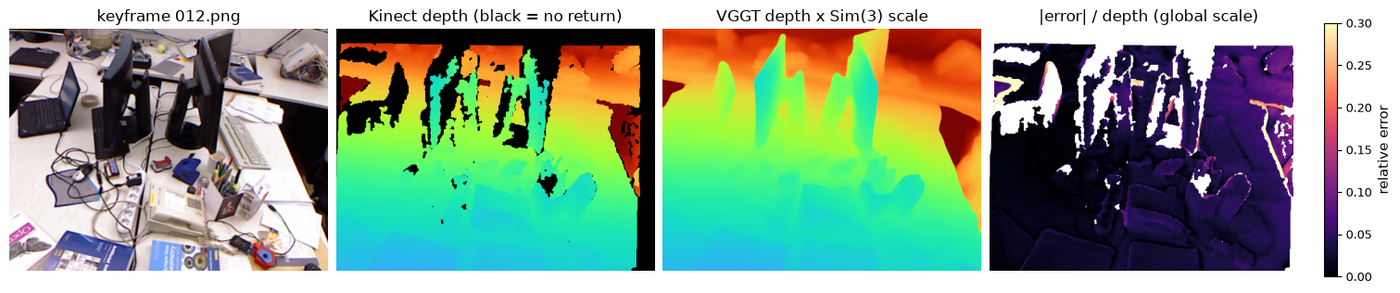

In [6]:
# --- One keyframe: RGB, Kinect depth, VGGT depth in metres (global scale), relative error ---
i = 12
r = recs["vggt"]
gt = ff3d.resize_depth_nearest(gt_depth[i], r.proc_hw)
pred_m = sim3["vggt"]["s"] * r.depth[i]
vmax = np.percentile(gt[gt > 0], 98)
rel_err = np.where(gt > 0, np.abs(pred_m - gt) / np.maximum(gt, 1e-6), np.nan)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.3))
axes[0].imshow(r.images[i])
axes[0].set_title(f"keyframe {tum.names[i]}")
axes[1].imshow(viz.colorize_depth(gt, vmin=0.3, vmax=vmax))
axes[1].set_title("Kinect depth (black = no return)")
axes[2].imshow(viz.colorize_depth(pred_m, vmin=0.3, vmax=vmax))
axes[2].set_title("VGGT depth x Sim(3) scale")
im = axes[3].imshow(rel_err, cmap="magma", vmin=0, vmax=0.3)
axes[3].set_title("|error| / depth (global scale)")
for ax in axes:
    ax.axis("off")
fig.colorbar(im, ax=axes[3], shrink=0.85, label="relative error")
plt.show()

## 4. A metric point cloud from a trajectory alignment
The reference cloud fuses the Kinect depth of the 24 keyframes with their motion-capture poses,
$X_w = T_{wc}^{\text{gt}}\,\big(z\,K^{-1}[u,v,1]^\top\big)$, in metres. Each method's cloud is
its own depth unprojected with its own cameras, then mapped to the mocap frame by the
Sim(3) $(s, R, \mathbf t)$ of section 3. Only pixels with a Kinect return are used on both sides,
so both clouds cover the same surfaces. Both are voxel-downsampled to 1 cm, then

* **accuracy** = distance from each predicted point to the nearest reference point,
* **completeness** = distance from each reference point to the nearest predicted point.

These distances combine depth errors, camera errors and the alignment, which is exactly what a
robot fusing these outputs into a map would get.

In [7]:
# --- Reference cloud: Kinect depth + mocap poses (metres, mocap world frame) ---
from cvlab.geometry import invert_T
from cvlab.pointcloud import depth_to_points, voxel_downsample

VOXEL = 0.01  # 1 cm
ref_pts = []
for i in range(len(tum)):
    P, _ = depth_to_points(gt_depth[i], tum.ref_K[i], stride=2, max_depth=4.0)  # camera frame
    T_wc = invert_T(tum.ref_T_cw[i])
    ref_pts.append(P @ T_wc[:3, :3].T + T_wc[:3, 3])
ref_cloud, _ = voxel_downsample(np.concatenate(ref_pts), VOXEL)
print(f"reference cloud: {len(ref_cloud):,} points after {VOXEL * 100:.0f} cm voxels")

reference cloud: 297,656 points after 1 cm voxels


Now the same for every method. The helper `ff3d.recon_points` unprojects the depth with the
predicted $K$ and pose; the mask keeps the pixels where the Kinect also measured something.

In [8]:
# --- Predicted clouds in metres + accuracy / completeness against the reference ---
clouds, cloud_rows = {}, []
for m, r in recs.items():
    al = sim3[m]
    pts, cols = [], []
    for i in range(len(tum)):
        gt = ff3d.resize_depth_nearest(gt_depth[i], r.proc_hw)
        P_cam, c = depth_to_points(r.depth[i], r.K[i], rgb=r.images[i],
                                   mask=(gt > 0) & (gt < 4.0), stride=2)
        T_wc = invert_T(r.T_cw[i])
        pts.append(P_cam @ T_wc[:3, :3].T + T_wc[:3, 3])
        cols.append(c)
    P_m = ff3d.sim3_apply(np.concatenate(pts), al["s"], al["R"], al["t"])  # -> metres
    P_ds, C_ds = voxel_downsample(P_m, VOXEL, colors=np.concatenate(cols))
    clouds[m] = (P_ds, C_ds)
    ch = ff3d.chamfer(P_ds, ref_cloud)
    cloud_rows.append({"method": ff3d.METHOD_LABELS[m],
                       "ATE (cm)": 100 * np.sqrt(np.mean(al["centre_err"] ** 2)),
                       "accuracy median (cm)": 100 * ch["acc_median"],
                       "completeness median (cm)": 100 * ch["comp_median"],
                       "Chamfer mean (cm)": 100 * ch["chamfer_mean"], "points": len(P_ds)})
cloud_table = pd.DataFrame(cloud_rows).set_index("method")
cloud_table.round(2)

,ATE (cm),accuracy median (cm),completeness median (cm),Chamfer mean (cm),points
method,,,,,
VGGT-1B,1.51,1.73,2.65,4.24,189942
DA3-Base (cam head),2.19,2.39,2.82,5.01,232824
DA3-Base (ray head),2.07,2.64,3.13,5.31,221937
DA3-Large-1.1 (cam head),1.11,1.70,2.46,4.01,200920
DA3-Large-1.1 (ray head),1.00,1.76,2.52,4.10,199636


## 5. Export the metric VGGT cloud
The VGGT cloud, now in metres and in the mocap world frame, is written to `outputs/` (gitignored).
Unlike notebook 01's export, it can be overlaid on the TUM ground truth in any 3D viewer.

In [9]:
# --- Write the metric VGGT point cloud of the desk to outputs/ ---
from cvlab.pointcloud import write_ply

ply = write_ply(outputs_dir(PROJECT, create=True) / "tum_desk_vggt_metric.ply", *clouds["vggt"])
print("wrote", ff3d.rel(ply), f"({len(clouds['vggt'][0]):,} points, metres)")

wrote outputs/10_feedforward_3d/tum_desk_vggt_metric.ply (189,942 points, metres)


## Results
### Runtime, memory and accuracy vs number of frames
All runs on the RTX 5060 Laptop GPU (8 GB). Crosses mark the first frame count that ran out of
memory. The dashed line is the 8 GiB of the card.

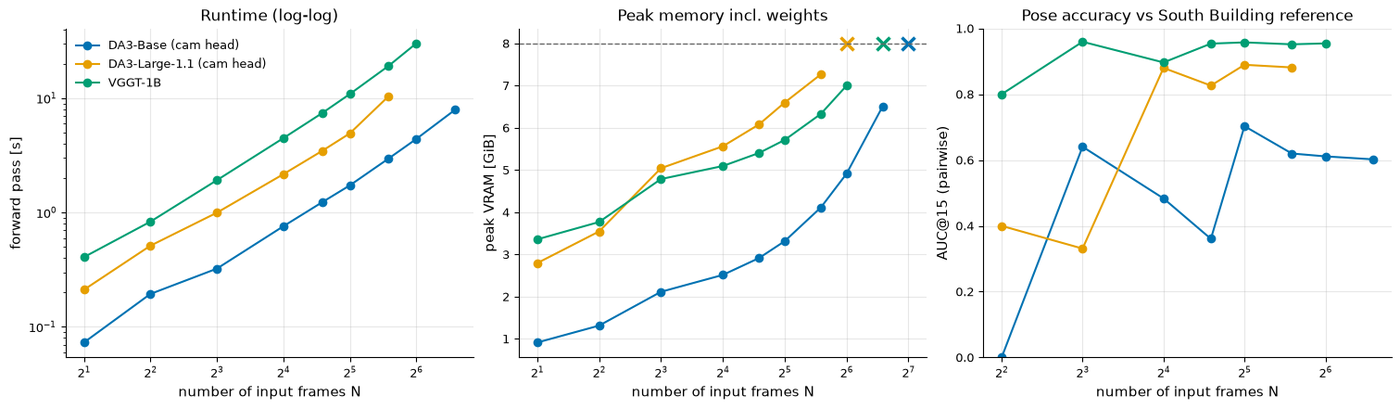

In [10]:
# --- Three panels: forward time, peak VRAM and AUC@15 vs N (log x axis) ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for k, (m, d) in enumerate(fits.groupby("method", sort=False)):
    style = {"marker": "o", "color": viz.color(k, unit=True), "label": ff3d.METHOD_LABELS[m]}
    axes[0].plot(d.n_frames, d.runtime_s, **style)
    axes[1].plot(d.n_frames, d.peak_vram_mb / 1024, **style)
    axes[2].plot(d.n_frames, d["auc@15"], **style)
    for _, r in ooms[ooms.method == m].iterrows():
        axes[1].plot(r.n_frames, 8.0, "x", ms=10, mew=2.5, color=viz.color(k, unit=True))
axes[1].axhline(8.0, ls="--", color="0.4", lw=1)
for ax, ylabel, title in zip(axes, ["forward pass [s]", "peak VRAM [GiB]", "AUC@15 (pairwise)"],
                             ["Runtime (log-log)", "Peak memory incl. weights",
                              "Pose accuracy vs South Building reference"]):
    ax.set_xscale("log", base=2)
    ax.set_xlabel("number of input frames N")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].set_yscale("log")
axes[2].set_ylim(0, 1)
axes[0].legend(loc="upper left")
viz.savefig(fig, PROJECT, "scaling_frames")
plt.show()

### Metric geometry on TUM fr1_desk
Left: the Kinect + mocap reference cloud. Middle and right: VGGT and DA3-Large-1.1 (ray head)
clouds after the Sim(3) alignment, all in metres, seen from above, with the reference camera
path. Below: the depth and point-cloud errors of every method.

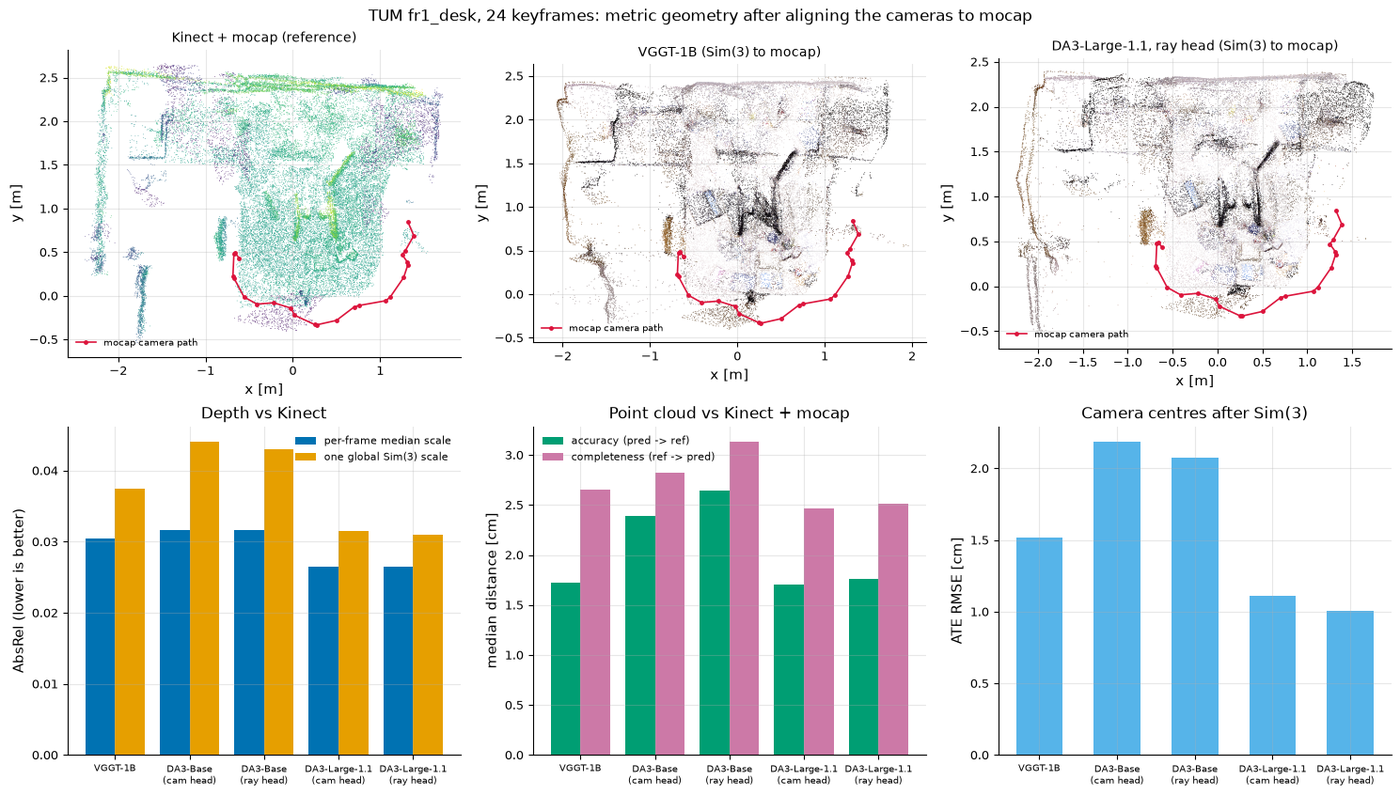

In [11]:
# --- Top-down renders of reference vs predicted metric clouds + error bars ---
rng = np.random.default_rng(0)
C_gt = ff3d.camera_centers(tum.ref_T_cw)
fig = plt.figure(figsize=(15, 8.6))
panels = [("Kinect + mocap (reference)", ref_cloud, None),
          ("VGGT-1B (Sim(3) to mocap)", *clouds["vggt"]),
          ("DA3-Large-1.1, ray head (Sim(3) to mocap)", *clouds["da3-large-ray"])]
for k, (title, P, C) in enumerate(panels):
    ax = fig.add_subplot(2, 3, k + 1)
    idx = rng.choice(len(P), min(len(P), 40000), replace=False)
    ax.scatter(P[idx, 0], P[idx, 1], s=0.3, c=C[idx] if C is not None else P[idx, 2],
               cmap=None if C is not None else "viridis", linewidths=0)
    ax.plot(C_gt[:, 0], C_gt[:, 1], "-o", ms=2.5, lw=1.2, color="crimson", label="mocap camera path")
    ax.set_aspect("equal")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_title(title, fontsize=10)
    ax.legend(loc="lower left", fontsize=7.5)
labels = [ff3d.METHOD_LABELS[m].replace(" (", "\n(") for m in methods]
x = np.arange(len(methods))
ax = fig.add_subplot(2, 3, 4)
ax.bar(x - 0.2, depth_table["AbsRel per-frame"], 0.4, label="per-frame median scale",
       color=viz.color(0, unit=True))
ax.bar(x + 0.2, depth_table["AbsRel global"], 0.4, label="one global Sim(3) scale",
       color=viz.color(1, unit=True))
ax.set_xticks(x, labels, fontsize=7)
ax.set_ylabel("AbsRel (lower is better)")
ax.set_title("Depth vs Kinect")
ax.legend(fontsize=8)
ax = fig.add_subplot(2, 3, 5)
ax.bar(x - 0.2, cloud_table["accuracy median (cm)"], 0.4, label="accuracy (pred -> ref)",
       color=viz.color(2, unit=True))
ax.bar(x + 0.2, cloud_table["completeness median (cm)"], 0.4, label="completeness (ref -> pred)",
       color=viz.color(3, unit=True))
ax.set_xticks(x, labels, fontsize=7)
ax.set_ylabel("median distance [cm]")
ax.set_title("Point cloud vs Kinect + mocap")
ax.legend(fontsize=8)
ax = fig.add_subplot(2, 3, 6)
ax.bar(x, cloud_table["ATE (cm)"], 0.6, color=viz.color(4, unit=True))
ax.set_xticks(x, labels, fontsize=7)
ax.set_ylabel("ATE RMSE [cm]")
ax.set_title("Camera centres after Sim(3)")
fig.suptitle("TUM fr1_desk, 24 keyframes: metric geometry after aligning the cameras to mocap")
fig.tight_layout()
viz.savefig(fig, PROJECT, "tum_metric_geometry")
plt.show()

### Summary table

In [12]:
# --- One table with the scaling fit and the TUM metric-geometry numbers ---
# The frame budget belongs to the network (model key), shared by its camera and ray heads.
summary = depth_table[["Sim(3) scale (m / unit)", "AbsRel per-frame", "delta1 per-frame",
                       "AbsRel global", "delta1 global"]].join(
    cloud_table[["ATE (cm)", "accuracy median (cm)", "completeness median (cm)",
                 "Chamfer mean (cm)"]])
largest = fits.groupby("method").n_frames.max()  # keyed by model: vggt, da3-base, da3-large
summary["largest N that fit"] = [largest.get(ff3d.METHODS[m][0], np.nan) for m in methods]
summary.round(3)

,Sim(3) scale (m / unit),AbsRel per-frame,delta1 per-frame,AbsRel global,delta1 global,ATE (cm),accuracy median (cm),completeness median (cm),Chamfer mean (cm),largest N that fit
method,,,,,,,,,,
VGGT-1B,1.491,0.030,0.978,0.037,0.978,1.514,1.726,2.651,4.241,64
DA3-Base (cam head),1.424,0.032,0.987,0.044,0.987,2.185,2.394,2.822,5.008,96
DA3-Base (ray head),1.421,0.032,0.987,0.043,0.987,2.073,2.643,3.131,5.312,96
DA3-Large-1.1 (cam head),1.217,0.026,0.988,0.031,0.988,1.108,1.700,2.461,4.012,48
DA3-Large-1.1 (ray head),1.216,0.026,0.988,0.031,0.988,1.004,1.763,2.515,4.101,48


**Takeaways**

- **Frame budget of an 8 GB card** (bf16 VGGT backbone, DA3 at 504 px): VGGT-1B fits 64
  frames (7166 MiB peak, 30.2 s forward) and runs out of memory at 96; DA3-Base fits 96
  (6667 MiB, 7.9 s) and runs out at 128; DA3-Large-1.1 fits 48 (7441 MiB, 10.4 s) and runs out
  of memory at 64. Each extra frame
  costs about 40-54 MiB at these resolutions. Beyond that budget you need chunking with
  overlapping frames, a lower resolution or a bigger GPU.
- **Runtime grows faster than linearly** (fitted exponent 1.3-1.4 for N >= 16): the global
  attention is already a large share of the work at a few dozen frames and will dominate
  beyond that. DA3-Base is 4-7x faster than VGGT at every N.
- **Few, widely spaced views are where the models differ most.** With frames spread over the
  whole building, VGGT already reaches AUC@15 0.80 with 4 views and 0.90-0.96 from 8 views on,
  while DA3-Large drops to 0.33-0.40 with 4-8 views and DA3-Base never exceeds 0.71 (0.36 at
  N = 24, vs 0.79 on the 24 closely spaced views of notebook 02). For a robot this
  means: feed views with overlap, and check the result rather than trusting a single pass.
- **Dense depth is good, and its scale is consistent.** Per-frame AbsRel against the Kinect is
  0.026-0.032 for every model. With one global scale from the camera trajectory it rises only to
  0.031 (DA3-Large), 0.037 (VGGT) and 0.043-0.044 (DA3-Base), so depth and camera translations
  agree on scale to within a few percent. $\delta_1$ saturates (0.98-0.99) and hardly separates
  the methods; AbsRel and the point-cloud distances do.
- **Metric point clouds at the 2 cm level.** After the Sim(3) to mocap, the median distance from
  predicted points to the Kinect + mocap surface is 1.7-1.8 cm for VGGT and DA3-Large and
  2.4-2.6 cm for DA3-Base; completeness is 2.5-3.1 cm. The reference is itself a Kinect, with
  noise and holes, and the camera-centre ATE (1.0-2.2 cm) is part of these numbers.

## Exercises
Solutions: `projects/10_feedforward_3d/solutions/solutions_03.py`.

**Exercise 1 - confidence vs completeness.** Section 4 used every pixel with a Kinect return.
Filter VGGT's pixels by its depth confidence instead (keep the top 90 %, 70 %, 50 %, 30 %) and
plot the median accuracy against the median completeness. What does the confidence buy you?

In [13]:
# --- Exercise 1: accuracy / completeness trade-off of the confidence threshold ---
# TODO: for q in [0.1, 0.3, 0.5, 0.7]: mask = conf >= quantile(conf, q) & Kinect-valid,
#       rebuild the VGGT cloud as in section 4 and call ff3d.chamfer.

**Exercise 2 - depth head vs point-map head in metres.** Build VGGT's cloud from its
**point-map head** (`recs["vggt"].world_points`) instead of unprojecting the depth, apply the
same Sim(3), and compare accuracy and completeness with section 4.

In [14]:
# --- Exercise 2: point-map head as a metric cloud ---
# TODO: take world_points[i][mask] for each frame, apply ff3d.sim3_apply with sim3["vggt"],
#       voxel-downsample to 1 cm and score with ff3d.chamfer.

**Exercise 3 - known trajectory instead of predicted cameras.** A robot often knows its
trajectory (wheel odometry, VIO). Fuse VGGT's depth maps with the **mocap** poses instead of the
predicted ones (depth scaled by the Sim(3) scale $s$, intrinsics still VGGT's) and compare the
accuracy and completeness with section 4. How much of the error came from the cameras?

In [15]:
# --- Exercise 3: predicted depth + ground-truth poses ---
# TODO: unproject s * depth with VGGT's K, transform with invert_T(tum.ref_T_cw[i]) and
#       score with ff3d.chamfer against ref_cloud.